# YOLO: estado de EPP por persona

Analizar entrenamiento, detección de las cuatro clases y equivalencia del modelo ONNX. Ejecutar previamente los comandos de entrenamiento, evaluación y exportación de `GUIA_COMANDOS.md`.

Cada persona tiene una sola etiqueta: sin casco ni chaleco, solo casco, solo chaleco o ambos. «EPP completo» significa casco y chaleco visibles.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'train.py').is_file():
    ROOT = ROOT / 'deep_learning/03_deteccion_epp_yolo'
assert (ROOT / 'train.py').is_file(), 'Abrir el notebook desde la práctica o la raíz del repositorio.'
RUN_NAME = 'yolo11n_ppe'  # Cambiar a yolo11n_clase para el entrenamiento del grupo.
RUN = ROOT / 'runs' / RUN_NAME
DATASET = ROOT / 'data/ppe_four'
selection = json.loads((RUN / 'selection.json').read_text())
print('Etapa seleccionada:', selection['selected_run'])
display(pd.DataFrame(json.loads((DATASET / 'audit_report.json').read_text())['partitions']).T)

Etapa seleccionada: finetune


,images,empty_images,objects
train,611,0,"[143, 135, 241, 755]"
val,131,0,"[34, 31, 52, 162]"
test,131,0,"[30, 34, 53, 151]"


## Curvas de aprendizaje

Comparar la pérdida de entrenamiento con la de validación y revisar mAP durante ambas etapas. La selección usa exclusivamente validación; prueba se reserva para la evaluación final.

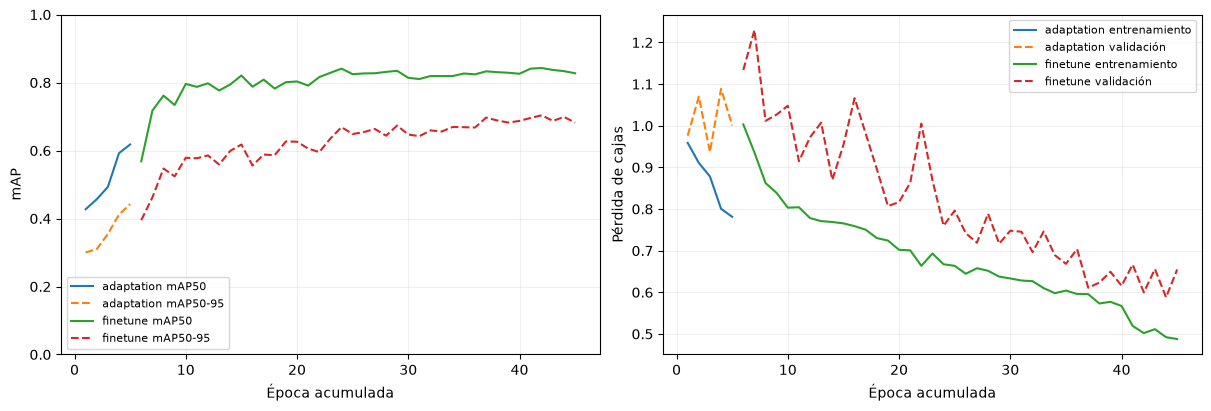

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
offset = 0
for stage in ['adaptation', 'finetune']:
    history = pd.read_csv(RUN / stage / 'results.csv')
    history.columns = history.columns.str.strip()
    epochs = history.index + 1 + offset
    axes[0].plot(epochs, history['metrics/mAP50(B)'], label=stage + ' mAP50')
    axes[0].plot(epochs, history['metrics/mAP50-95(B)'], '--', label=stage + ' mAP50-95')
    axes[1].plot(epochs, history['train/box_loss'], label=stage + ' entrenamiento')
    axes[1].plot(epochs, history['val/box_loss'], '--', label=stage + ' validación')
    offset += len(history)
axes[0].set(ylabel='mAP', xlabel='Época acumulada', ylim=(0, 1))
axes[1].set(ylabel='Pérdida de cajas', xlabel='Época acumulada')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
plt.show()

## Métricas por clase

IoU es el área de intersección de dos cajas dividida entre el área de su unión. AP50 usa IoU de 0.50; AP50–95 promedia umbrales de 0.50 a 0.95. mAP promedia AP entre clases.

La precisión indica qué proporción de las detecciones es correcta; recall indica qué proporción de las personas anotadas fue detectada con su clase correcta. Revisar los resultados de cada estado y su número de ejemplos.

In [3]:
ap = json.loads((RUN / 'metrics_test.json').read_text())
operating = json.loads((RUN / 'operating_test.json').read_text())
display(pd.Series(ap['metrics'], name='Prueba'))
display(pd.DataFrame(ap['per_class']))
display(pd.DataFrame(operating['per_class']))

metrics/precision(B)    0.875464
metrics/recall(B)       0.821118
metrics/mAP50(B)        0.883788
metrics/mAP50-95(B)     0.727977
fitness                 0.727977
Name: Prueba, dtype: float64

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP75,mAP50-95
0,persona,23,30,0.95481,0.70449,0.81077,0.80883,0.69086,0.65259
1,persona_con_casco,26,34,0.88198,0.87925,0.88061,0.89955,0.89480,0.78061
2,persona_con_chaleco,32,53,0.80835,0.77358,0.79059,0.86948,0.81214,0.70195
3,persona_epp_completo,82,151,0.85671,0.92715,0.89054,0.95728,0.89293,0.77676


,class,precision,recall,f1,tp,fp,fn
0,persona,1.000000,0.666667,0.800000,20,0,10
1,persona_con_casco,0.866667,0.764706,0.812500,26,4,8
2,persona_con_chaleco,0.878049,0.679245,0.765957,36,5,17
3,persona_epp_completo,0.956204,0.867550,0.909722,131,6,20


## Matriz de confusión

El umbral de confianza se seleccionó en validación y se mantuvo fijo en prueba. Las filas son referencia y las columnas son predicción. `background` representa personas omitidas o detecciones sin correspondencia; no es una quinta clase entrenada. Su diagonal no cuenta verdaderos negativos.

Confianza: 0.65 | IoU de correspondencia: 0.5


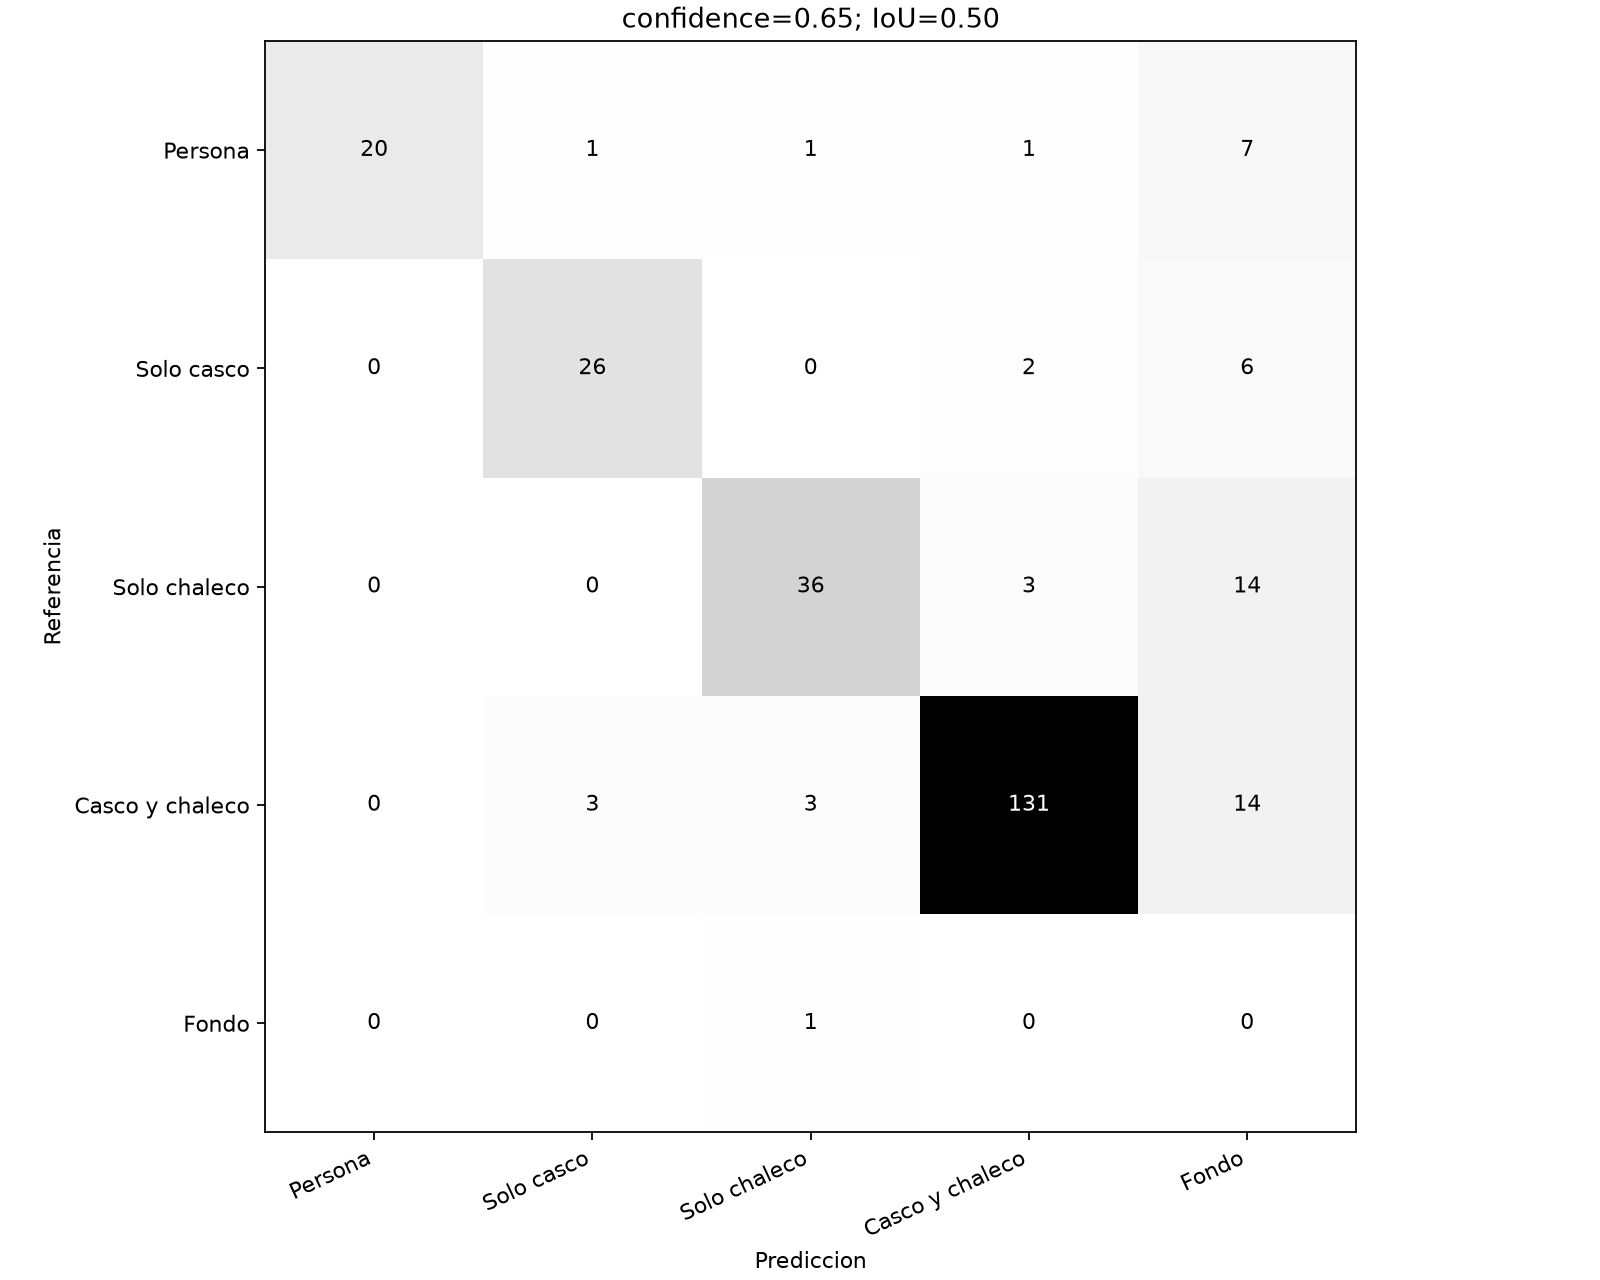

In [4]:
print('Confianza:', operating['confidence'], '| IoU de correspondencia:', operating['matching_iou'])
display(Image(filename=str(RUN / 'operating_test_matrix.png')))

## Ejemplos y errores

Las cajas blancas representan las anotaciones y las de color son predicciones. Identificar errores de localización, confusiones de estado y personas omitidas. El segundo panel reúne imágenes con más errores. Evitar usar prueba para elegir nuevos hiperparámetros y después presentar esa misma prueba como independiente.

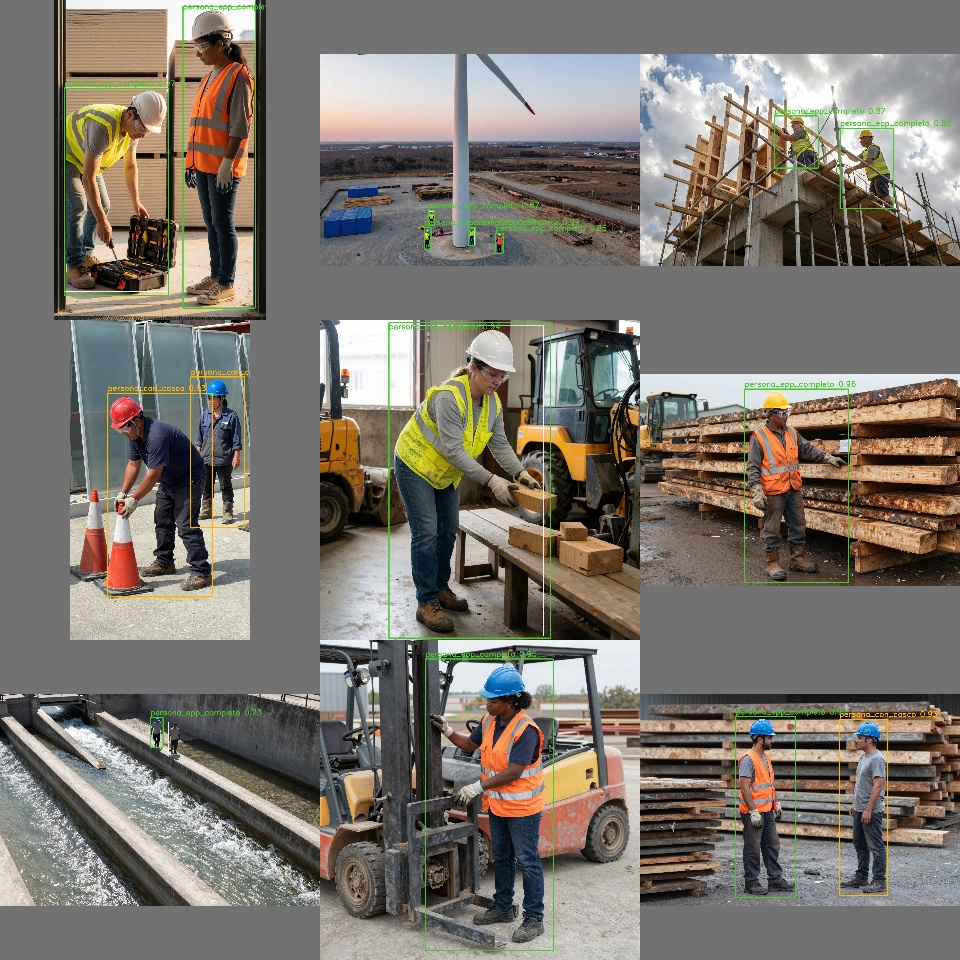

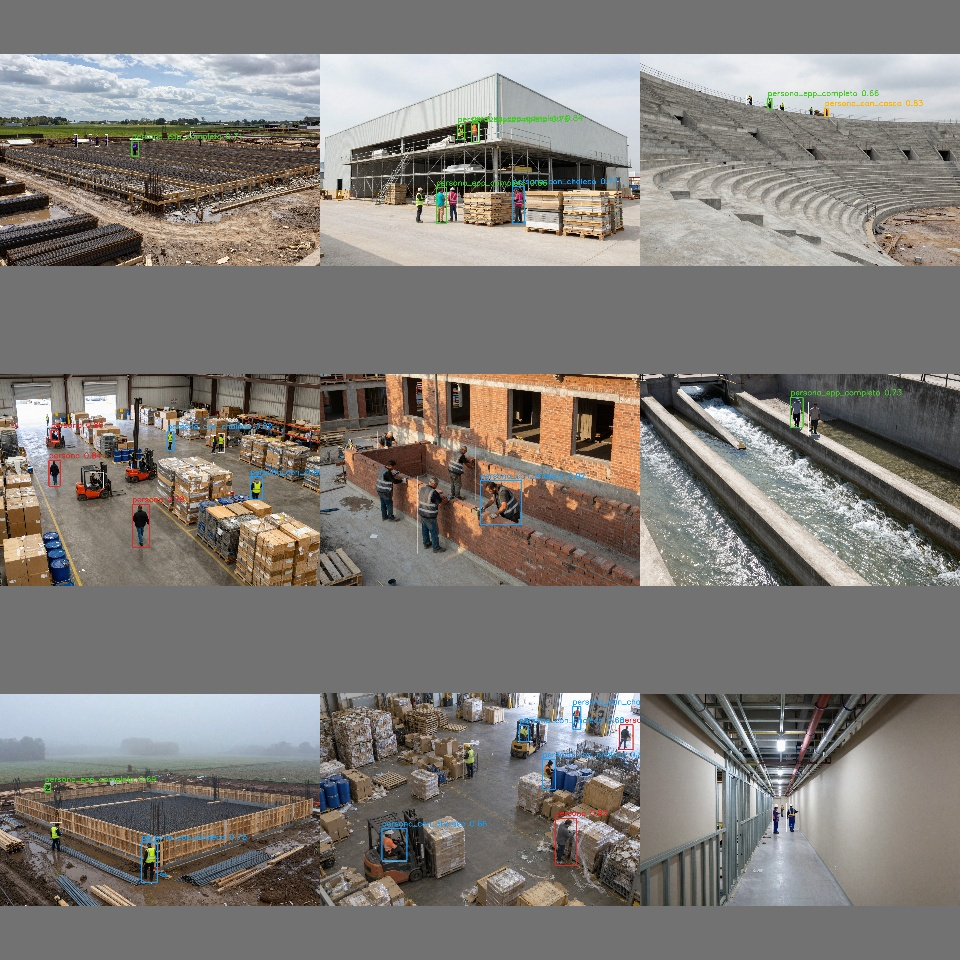

In [5]:
display(Image(filename=str(RUN / 'analysis/test_examples.jpg')))
display(Image(filename=str(RUN / 'analysis/test_failures.jpg')))

## Comprobación de ONNX

La exportación conserva el preprocesamiento y compara probabilidades, coordenadas y detecciones con PyTorch en imágenes de validación. La resolución original puede cambiar; la entrada de la red continúa siendo la definida en el modelo.

{'split': 'val',
 'images': 24,
 'detections': 35,
 'max_raw_coordinate_error_pixels': 0.00189208984375,
 'max_raw_probability_error': 9.119510650634766e-06,
 'coordinate_tolerance_pixels': 0.05,
 'probability_tolerance': 0.001,
 'unmatched_native_onnx_detections': 0,
 'matched_native_onnx_detections': 35,
 'max_box_error_original_pixels': 0.00048828125,
 'status': 'PASS'}

,class_id,confidence,box
0,0,0.964964,"[154.428055, 53.003075, 1147.231689, 1086]"


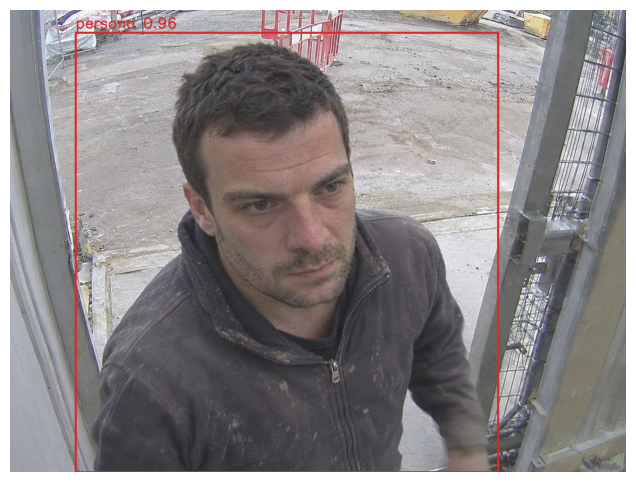

Inferencia ONNX en esta PC: 37.5 ms


In [6]:
if not (RUN / 'onnx_validation.json').is_file():
    print('Ejecutar el paso de exportacion de GUIA_COMANDOS.md y volver a ejecutar esta celda.')
else:
    validation = json.loads((RUN / 'onnx_validation.json').read_text())
    display(validation)
    assert validation['status'] == 'PASS'
    
    import sys
    sys.path.insert(0, str(ROOT))
    import cv2
    from yolo_inference import PPEDetector
    from infer import annotate
    PACKAGE = ROOT / 'runs' / ('pc_ppe' if RUN_NAME == 'yolo11n_ppe' else 'pc_clase')
    metadata = json.loads((PACKAGE / 'model.json').read_text())
    detector = PPEDetector(PACKAGE / 'model.onnx', metadata['confidence'])
    photo = sorted((PACKAGE / 'samples').glob('*.jpg'))[0]
    bgr = cv2.imread(str(photo))
    detections, milliseconds = detector.predict(bgr)
    display(pd.DataFrame(detections))
    plt.figure(figsize=(9, 6))
    plt.imshow(cv2.cvtColor(annotate(bgr, detections, metadata['classes']), cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
    print(f'Inferencia ONNX en esta PC: {milliseconds:.1f} ms')

## Interpretación para una aplicación de robótica

Las cuatro clases describen equipo visible. Una oclusión, un casco sostenido en la mano o una prenda reflectante distinta pueden producir ambigüedades. La fuente incluye fotografías e imágenes generadas y las etiquetas de estado se derivan de anotaciones de persona y equipo. Los resultados de la partición interna no garantizan el mismo rendimiento con una webcam nueva.